# Heart Deases Classification

In [119]:
#  Import required libraries
import pandas as pd

#  UCI Heart Disease dataset URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

#  Column names from UCI documentation
columns = [
    'age','sex','cp','trestbps','chol','fbs','restecg',
    'thalach','exang','oldpeak','slope','ca','thal','num'
]

#  Load dataset
df = pd.read_csv(url, names=columns)

#  Save as CSV (openable in Excel)
df.to_csv("heart_disease_raw.csv", index=False)

print(" Dataset loaded and saved as 'heart_disease_raw.csv'")
print("Shape:", df.shape)
df.head()


 Dataset loaded and saved as 'heart_disease_raw.csv'
Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [120]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df)

https://docs.google.com/spreadsheets/d/1TIYu9P672FVAg7N2zhf13rw26MuKBq7qKqMLBTfifMg/edit#gid=0


In [121]:
#  Dataset information
print("=== Dataset Info ===")
print(df.info())
print("\n=== First 5 rows ===")
display(df.head())

# Check missing or invalid values ('?' means missing)
print("\n=== Missing values before handling ===")
print((df == '?').sum())


=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        303 non-null    object 
 12  thal      303 non-null    object 
 13  num       303 non-null    int64  
dtypes: float64(11), int64(1), object(2)
memory usage: 33.3+ KB
None

=== First 5 rows ===


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



=== Missing values before handling ===
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


In [122]:
import numpy as np

# Replace '?' with NaN
df.replace('?', np.nan, inplace=True)

# Convert numeric columns that may contain strings to numeric
for col in ['ca', 'thal']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Check how many nulls now
print("\n=== Missing values after '?' -> NaN conversion ===")
print(df.isnull().sum())

# Fill numeric nulls with median
for col in ['ca', 'thal']:
    df[col].fillna(df[col].median(), inplace=True)

print("\n Missing values handled successfully!")
print(df.isnull().sum())



=== Missing values after '?' -> NaN conversion ===
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

 Missing values handled successfully!
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64


/tmp/ipython-input-3226804484.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)


In [123]:
# Check for duplicate rows
duplicates = df.duplicated().sum()
print("Duplicate rows:", duplicates)

# Remove duplicates if found
if duplicates > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(" Duplicates removed. New shape:", df.shape)
else:
    print(" No duplicate rows found.")


Duplicate rows: 0
 No duplicate rows found.


In [124]:
# Convert 'num' column to binary target (0 = no disease, 1 = disease)
df['target'] = df['num'].apply(lambda x: 1 if float(x) > 0 else 0)

# Drop original 'num'
df.drop(columns=['num'], inplace=True)

# Show distribution
print("Target column created (binary)")
print(df['target'].value_counts())


Target column created (binary)
target
0    164
1    139
Name: count, dtype: int64


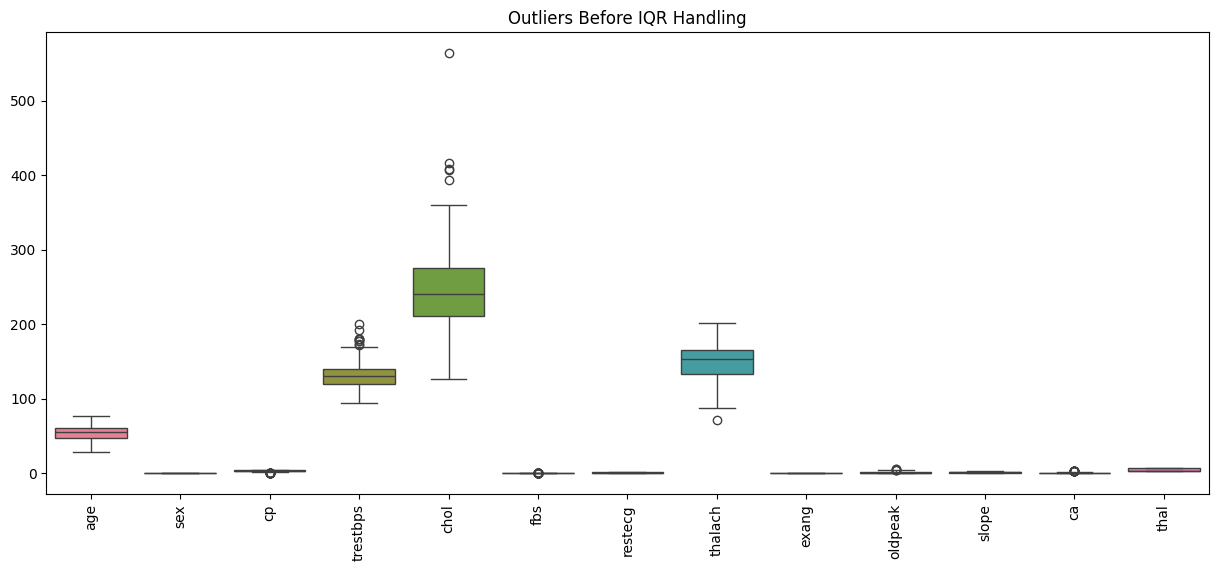

Outliers handled (capped using IQR method)


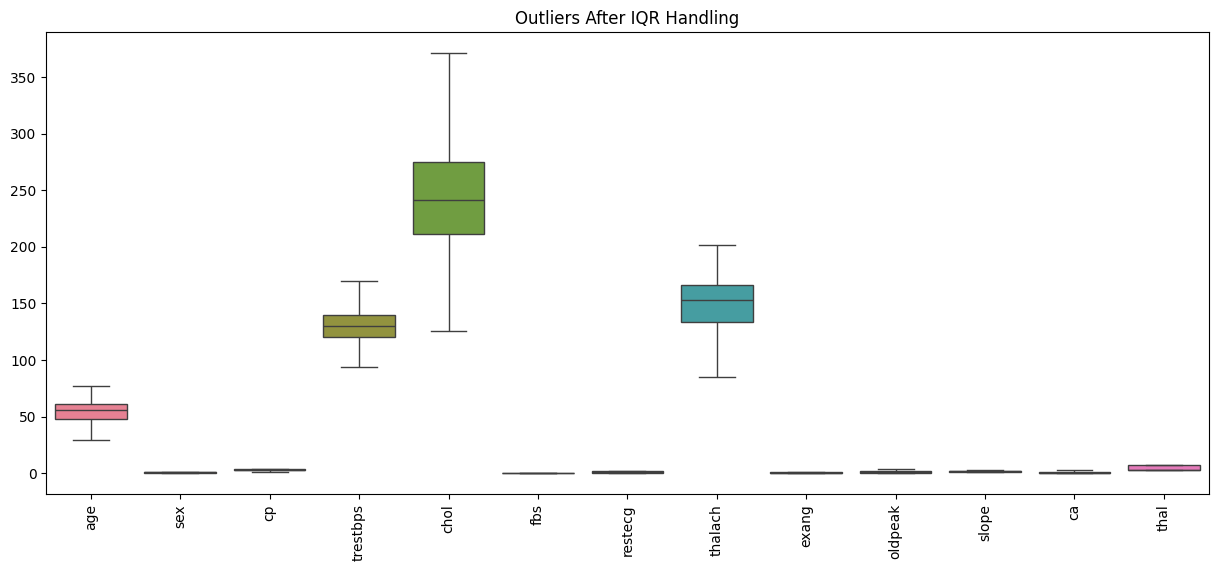

In [125]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# select numeric columns except target
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
numeric_cols.remove('target')

# =========================
# 1️⃣ BOXPLOT BEFORE OUTLIER HANDLING
# =========================
plt.figure(figsize=(15, 6))
sns.boxplot(data=df[numeric_cols])
plt.xticks(rotation=90)
plt.title("Outliers Before IQR Handling")
plt.show()


# =========================
# 2️⃣ IQR OUTLIER HANDLING (CAPPING)
# =========================
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] < lower, lower, df[col])
    df[col] = np.where(df[col] > upper, upper, df[col])

print("Outliers handled (capped using IQR method)")


# =========================
# 3️⃣ BOXPLOT AFTER OUTLIER HANDLING
# =========================
plt.figure(figsize=(15, 6))
sns.boxplot(data=df[numeric_cols])
plt.xticks(rotation=90)
plt.title("Outliers After IQR Handling")
plt.show()


In [126]:
# One-hot encode categorical columns
df_encoded = pd.get_dummies(df, columns=['cp', 'restecg', 'slope', 'thal'], drop_first=True)

print(" One-hot encoding done.")
print("New shape:", df_encoded.shape)
df_encoded.head()


 One-hot encoding done.
New shape: (303, 19)


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,target,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0,slope_2.0,slope_3.0,thal_6.0,thal_7.0
0,63.0,1.0,145.0,233.0,0.0,150.0,0.0,2.3,0.0,0,False,False,False,False,True,False,True,True,False
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,2.5,1,False,False,True,False,True,True,False,False,False
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,1,False,False,True,False,True,True,False,False,True
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,0,False,True,False,False,False,False,True,False,False
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,0,True,False,False,False,True,False,False,False,False


In [127]:
from sklearn.preprocessing import MinMaxScaler, Normalizer

# Split features and target
X = df_encoded.drop(columns=['target'])
y = df_encoded['target']

# Apply MinMax scaling
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# Apply normalization
normalizer = Normalizer()
X_normalized = pd.DataFrame(normalizer.fit_transform(X_scaled), columns=X.columns)

print(" Scaling and normalization done.")
X_normalized.head()


 Scaling and normalization done.


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0,slope_2.0,slope_3.0,thal_6.0,thal_7.0
0,0.294549,0.415833,0.279046,0.181609,0.0,0.231413,0.000000,0.239104,0.000000,0.000000,0.000000,0.000000,0.0,0.415833,0.000000,0.415833,0.415833,0.000000
1,0.280118,0.353834,0.307277,0.231075,0.0,0.070163,0.353834,0.132688,0.353834,0.000000,0.000000,0.353834,0.0,0.353834,0.353834,0.000000,0.000000,0.000000
2,0.277727,0.350814,0.120015,0.147485,0.0,0.132397,0.350814,0.228029,0.280651,0.000000,0.000000,0.350814,0.0,0.350814,0.350814,0.000000,0.000000,0.350814
3,0.074280,0.445681,0.211112,0.225569,0.0,0.388664,0.000000,0.389971,0.000000,0.000000,0.445681,0.000000,0.0,0.000000,0.000000,0.445681,0.000000,0.000000
4,0.142811,0.000000,0.270590,0.181866,0.0,0.425084,0.000000,0.199936,0.000000,0.571245,0.000000,0.000000,0.0,0.571245,0.000000,0.000000,0.000000,0.000000


In [128]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Split features and target
X = df_encoded.drop(columns=['target'])
y = df_encoded['target']

X_train, X_test, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.2, random_state=42, stratify=y
)

# Balance the training set using SMOTE
print("Balancing using SMOTE on training data")
print("Before SMOTE class counts:", y_train.value_counts().to_dict())

sm = SMOTE(random_state=42)
X_train_bal, y_train_bal = sm.fit_resample(X_train, y_train) # Using normalized data for SMOTE

print("After SMOTE class counts:", pd.Series(y_train_bal).value_counts().to_dict())


print(" Data split into Train & Test sets")
print("Train shape:", X_train_bal.shape)
print("Test shape:", X_test.shape)

Balancing using SMOTE on training data
Before SMOTE class counts: {0: 131, 1: 111}
After SMOTE class counts: {1: 131, 0: 131}
 Data split into Train & Test sets
Train shape: (262, 18)
Test shape: (61, 18)


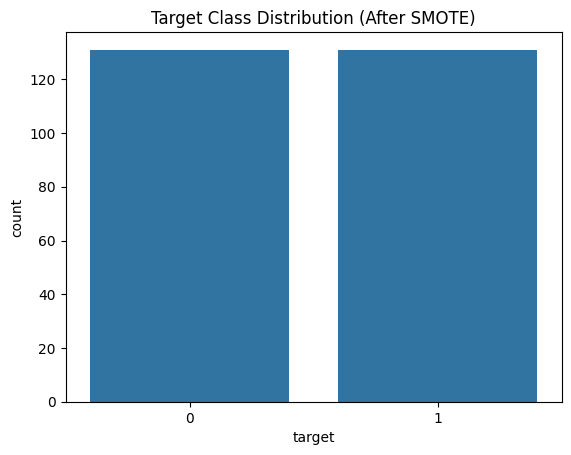

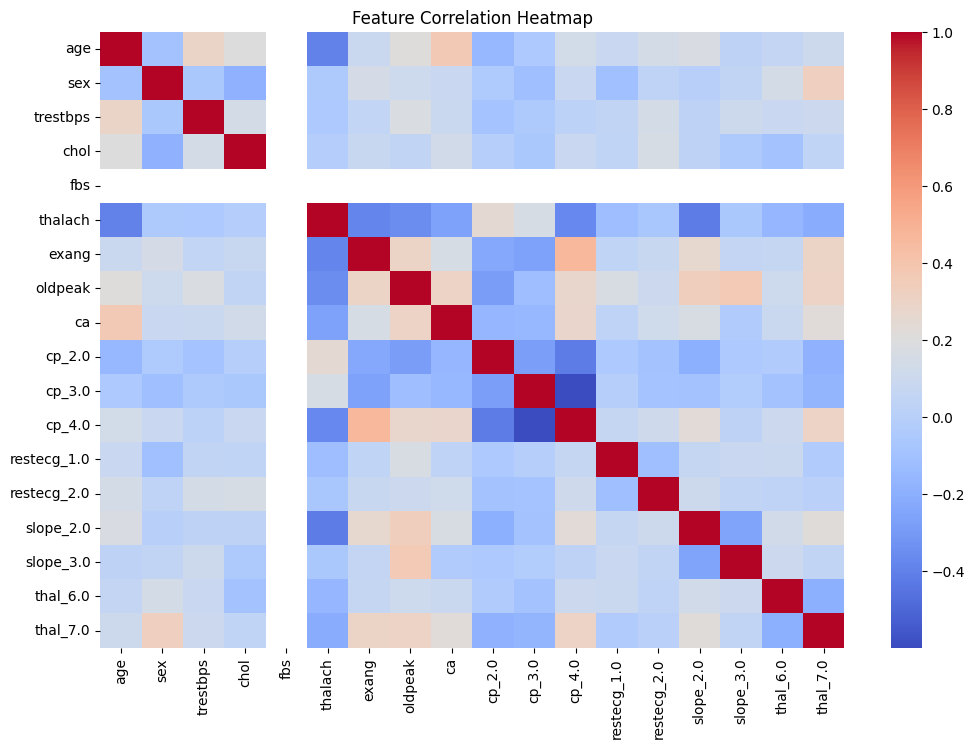

In [129]:
import seaborn as sns
import matplotlib.pyplot as plt

# Target distribution
sns.countplot(x=y_train_bal)
plt.title("Target Class Distribution (After SMOTE)")
plt.show()

# Correlation heatmap
plt.figure(figsize=(12,8))
sns.heatmap(X.corr(), cmap="coolwarm", annot=False)
plt.title("Feature Correlation Heatmap")
plt.show()

# Logistic Regression

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



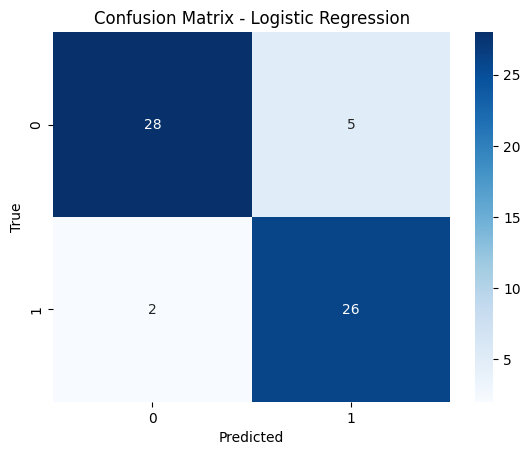

In [130]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)
y_pred = log_model.predict(X_test)

print("=== Logistic Regression ===")
print(classification_report(y_test, y_pred))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# Random Forest

=== Random Forest Classifier ===
              precision    recall  f1-score   support

           0       0.91      0.88      0.89        33
           1       0.86      0.89      0.88        28

    accuracy                           0.89        61
   macro avg       0.88      0.89      0.88        61
weighted avg       0.89      0.89      0.89        61



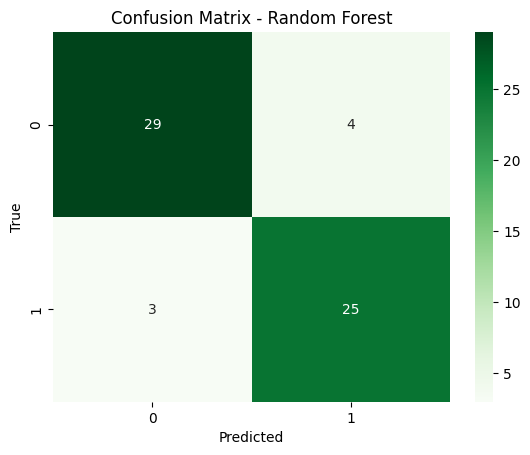

In [131]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

print("=== Random Forest Classifier ===")
print(classification_report(y_test, y_pred))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


# Decision Tree

=== Decision Tree Classifier ===
              precision    recall  f1-score   support

           0       0.88      0.67      0.76        33
           1       0.69      0.89      0.78        28

    accuracy                           0.77        61
   macro avg       0.79      0.78      0.77        61
weighted avg       0.79      0.77      0.77        61



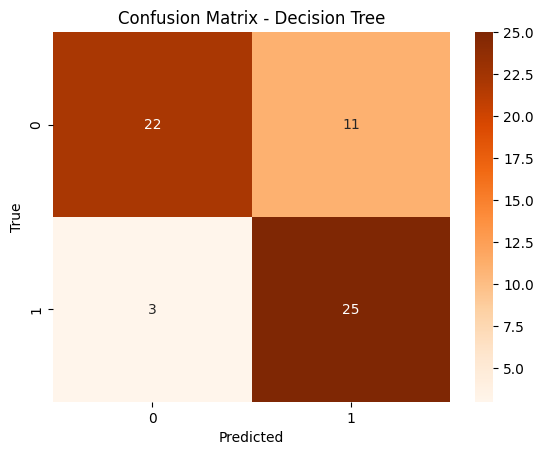

In [132]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(max_depth=8, random_state=42)
dt_model.fit(X_train, y_train)
y_pred = dt_model.predict(X_test)

print("=== Decision Tree Classifier ===")
print(classification_report(y_test, y_pred))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Oranges')
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# Gradient Boosting

=== Gradient Boosting ===
              precision    recall  f1-score   support

           0       0.97      0.85      0.90        33
           1       0.84      0.96      0.90        28

    accuracy                           0.90        61
   macro avg       0.90      0.91      0.90        61
weighted avg       0.91      0.90      0.90        61



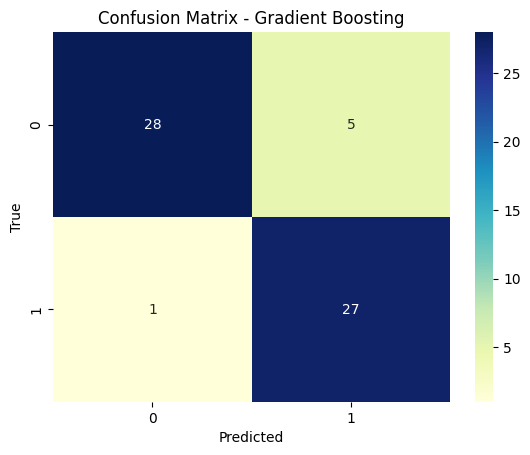

In [133]:
from sklearn.ensemble import  GradientBoostingClassifier
gb_model = GradientBoostingClassifier()
gb_model.fit(X_train, y_train)
y_pred = gb_model.predict(X_test)

print("=== Gradient Boosting ===")
print(classification_report(y_test, y_pred))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='YlGnBu')
plt.title("Confusion Matrix - Gradient Boosting")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# KNN with Hyperparameter Tuning

=== Best KNN Parameters === {'metric': 'minkowski', 'n_neighbors': 9, 'weights': 'uniform'}
=== KNN Classification Report ===
               precision    recall  f1-score   support

           0       1.00      0.85      0.92        33
           1       0.85      1.00      0.92        28

    accuracy                           0.92        61
   macro avg       0.92      0.92      0.92        61
weighted avg       0.93      0.92      0.92        61



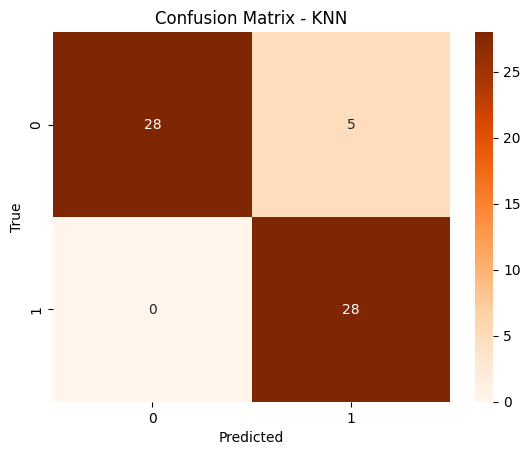

In [134]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Hyperparameter grid
knn_param_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'],
    'metric': ['minkowski', 'euclidean', 'manhattan']
}

# GridSearchCV
knn_model = GridSearchCV(KNeighborsClassifier(), knn_param_grid, cv=5, scoring='accuracy')
knn_model.fit(X_train, y_train)

# Predictions
y_pred_knn = knn_model.predict(X_test)

# Output
print("=== Best KNN Parameters ===", knn_model.best_params_)
print("=== KNN Classification Report ===\n", classification_report(y_test, y_pred_knn))

# Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Oranges')
plt.title("Confusion Matrix - KNN")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


# SVM with Hyperparameter Tuning

=== Best SVM Parameters === {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
=== SVM Classification Report ===
               precision    recall  f1-score   support

           0       0.88      0.85      0.86        33
           1       0.83      0.86      0.84        28

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61



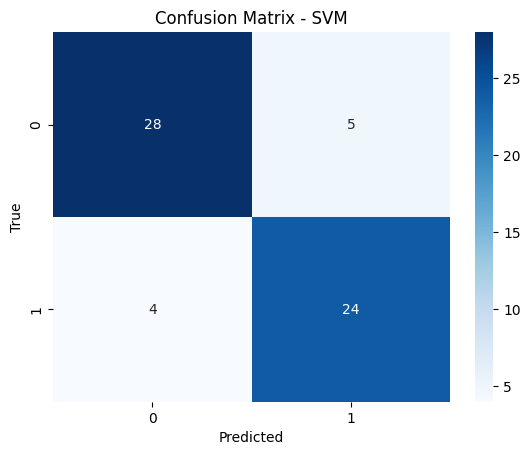

In [135]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Define hyperparameter grid
svm_param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['scale', 'auto']
}

# GridSearchCV
svm_model = GridSearchCV(SVC(random_state=42), svm_param_grid, cv=5, scoring='accuracy')
svm_model.fit(X_train, y_train)

# Predictions
y_pred_svm = svm_model.predict(X_test)

# Output
print("=== Best SVM Parameters ===", svm_model.best_params_)
print("=== SVM Classification Report ===\n", classification_report(y_test, y_pred_svm))

# Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - SVM")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


# AdaBoost with Hyperparameter Tuning

=== Best AdaBoost Parameters === {'learning_rate': 0.5, 'n_estimators': 100}
=== AdaBoost Classification Report ===
               precision    recall  f1-score   support

           0       0.93      0.79      0.85        33
           1       0.79      0.93      0.85        28

    accuracy                           0.85        61
   macro avg       0.86      0.86      0.85        61
weighted avg       0.86      0.85      0.85        61



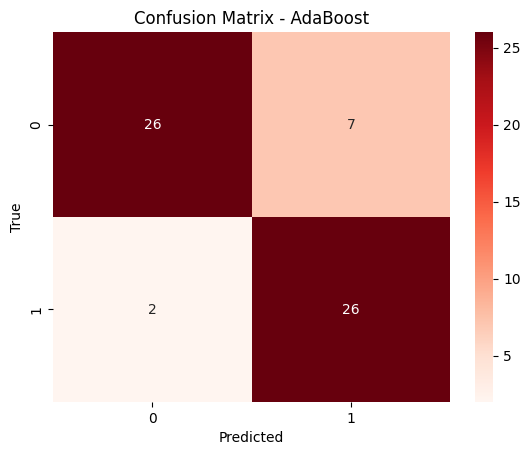

In [136]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Hyperparameter grid
ada_param_grid = {
    'n_estimators': [50, 100, 150, 200],
    'learning_rate': [0.01, 0.1, 0.5, 1]
}

# GridSearchCV
ada_model = GridSearchCV(AdaBoostClassifier(random_state=42), ada_param_grid, cv=5, scoring='accuracy')
ada_model.fit(X_train, y_train)

# Predictions
y_pred_ada = ada_model.predict(X_test)

# Output
print("=== Best AdaBoost Parameters ===", ada_model.best_params_)
print("=== AdaBoost Classification Report ===\n", classification_report(y_test, y_pred_ada))

# Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_ada), annot=True, fmt='d', cmap='Reds')
plt.title("Confusion Matrix - AdaBoost")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


# Naive Bayes

=== Naive Bayes Classifier ===
              precision    recall  f1-score   support

           0       0.81      0.39      0.53        33
           1       0.56      0.89      0.68        28

    accuracy                           0.62        61
   macro avg       0.68      0.64      0.61        61
weighted avg       0.69      0.62      0.60        61



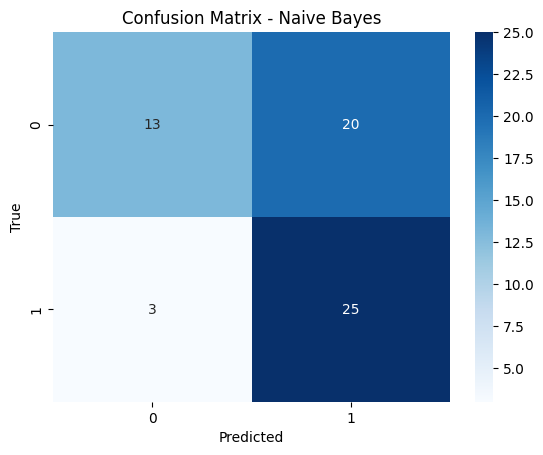

In [137]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
y_pred = nb_model.predict(X_test)

print("=== Naive Bayes Classifier ===")
print(classification_report(y_test, y_pred))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

=== Model Performance Comparison ===
                 Model  Accuracy  Precision    Recall  F1-Score
3                  KNN  0.918033   0.930452  0.918033  0.918033
7    Gradient Boosting  0.901639   0.909624  0.901639  0.901745
2        Random Forest  0.885246   0.885970  0.885246  0.885370
0  Logistic Regression  0.885246   0.889900  0.885246  0.885431
6             AdaBoost  0.852459   0.863991  0.852459  0.852459
4                  SVM  0.852459   0.853236  0.852459  0.852618
1        Decision Tree  0.770492   0.794827  0.770492  0.769008
5          Naive Bayes  0.622951   0.694558  0.622951  0.601447


/tmp/ipython-input-3437611675.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics_df, x="Model", y="Accuracy", palette="viridis")


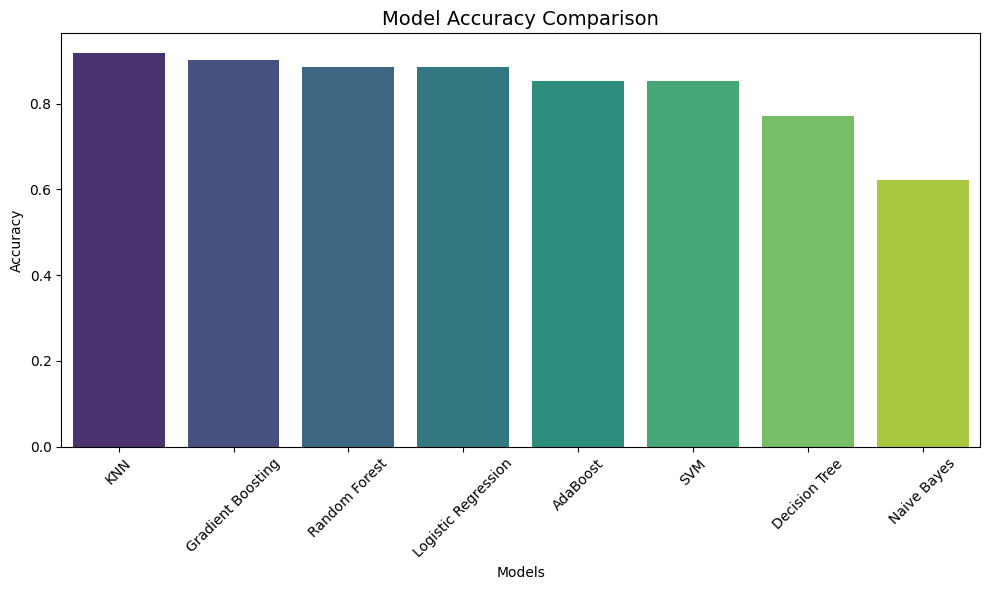

/tmp/ipython-input-3437611675.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics_df, x="Model", y="F1-Score", palette="magma")


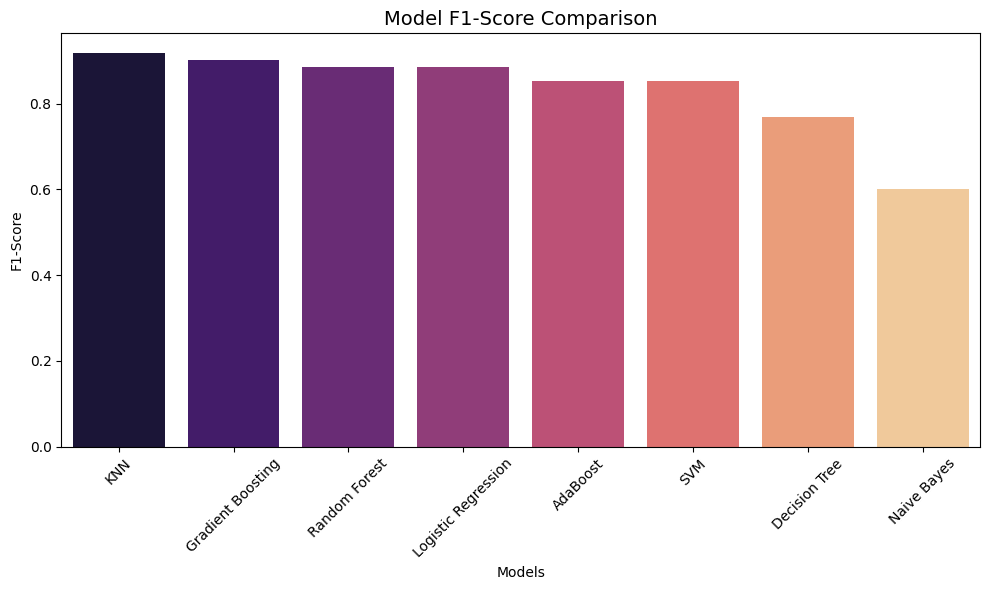

In [138]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Collect model names and predictions
models = {
    "Logistic Regression": log_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "KNN": knn_model,
    "SVM": svm_model,
    "Naive Bayes": nb_model,
    "AdaBoost": ada_model,
    "Gradient Boosting": gb_model
}

# Compute metrics
results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    results.append([name, acc, prec, rec, f1])

# Create DataFrame
import pandas as pd
metrics_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1-Score"])

# Sort by Accuracy
metrics_df = metrics_df.sort_values(by="Accuracy", ascending=False)

# Print table
print("=== Model Performance Comparison ===")
print(metrics_df)

# Plot bar chart
plt.figure(figsize=(10,6))
sns.barplot(data=metrics_df, x="Model", y="Accuracy", palette="viridis")
plt.title("Model Accuracy Comparison", fontsize=14)
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Optional: Plot F1-Score comparison too
plt.figure(figsize=(10,6))
sns.barplot(data=metrics_df, x="Model", y="F1-Score", palette="magma")
plt.title("Model F1-Score Comparison", fontsize=14)
plt.xlabel("Models")
plt.ylabel("F1-Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **ROC Curve**

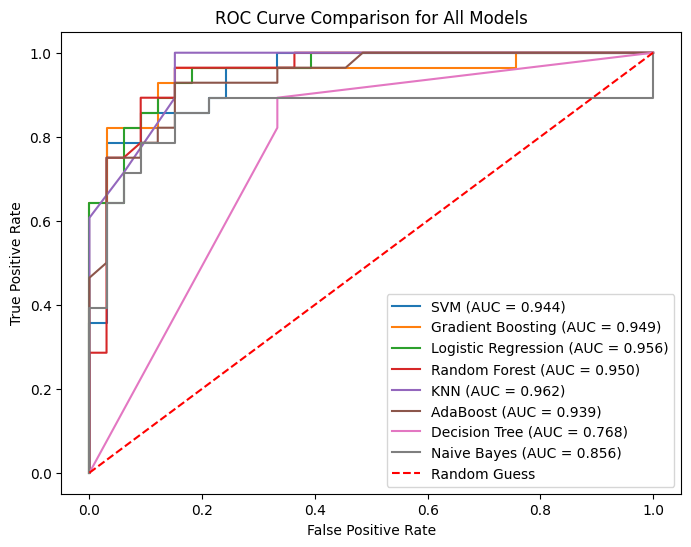

In [139]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# === All trained models (replace with your variable names) ===
models = {
    "SVM": svm_model,
    "Gradient Boosting": gb_model,
    "Logistic Regression": log_model,
    "Random Forest": rf_model,
    "KNN": knn_model,
    "AdaBoost": ada_model,
    "Decision Tree": dt_model,
    "Naive Bayes": nb_model
}

plt.figure(figsize=(8,6))

# === Loop through all models ===
for name, model in models.items():
    # For models with predict_proba
    if hasattr(model, "predict_proba"):
        y_pred_prob = model.predict_proba(X_test)[:, 1]
    else:
        # For models like SVM that use decision_function
        y_pred_prob = model.decision_function(X_test)

    fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')

# === Random guess line ===
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Guess')

# === Labels and Title ===
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison for All Models')
plt.legend(loc='lower right')
plt.show()


# Stacking Ensemble with SVM,GB & RF

# Why SVC with low accuracy still helps:

Diversity matters:

Even if SVC is not very accurate on its own, its predictions are different from KNN or Random Forest.

This diversity gives the meta model extra information to correct mistakes.

Meta model learns weights:

Logistic Regression (the meta model) doesn’t blindly average predictions.

It learns which base model to trust more for different situations.

Example: maybe KNN is good for one type of patient, SVC is good for another.

Complementary errors:

Models make different errors.

By combining them, stacking can reduce overall error, even if one base model is weak.

✅ So, even a low-accuracy model can improve the final ensemble because it adds unique perspectives that other models don’t capture.

Stacking Ensemble Accuracy: 0.9344262295081968
=== Stacking Ensemble Classification Report ===
              precision    recall  f1-score   support

           0       0.97      0.91      0.94        33
           1       0.90      0.96      0.93        28

    accuracy                           0.93        61
   macro avg       0.93      0.94      0.93        61
weighted avg       0.94      0.93      0.93        61



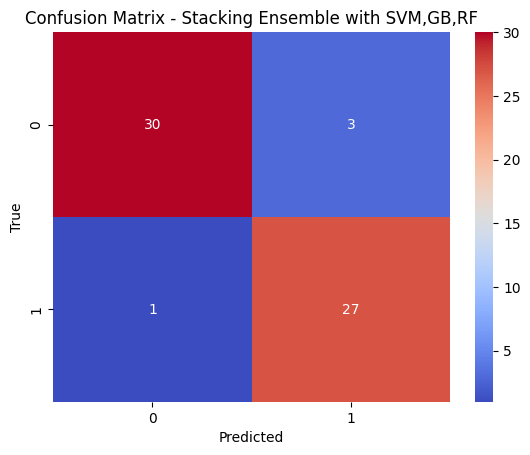

In [140]:
from sklearn.ensemble import StackingClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Base models
base_models = [
    ('svm', SVC(probability=True, kernel='rbf')),
    ('gb', GradientBoostingClassifier()),
    ('rf', RandomForestClassifier())
]

# Meta model
meta_model = LogisticRegression(max_iter=1000)

# Build Stacking Ensemble
stack_model = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model
)

# Train
stack_model.fit(X_train, y_train)

# Accuracy
print("Stacking Ensemble Accuracy:", stack_model.score(X_test, y_test))

# Predict
y_pred_stack = stack_model.predict(X_test)

# Classification Report
print("=== Stacking Ensemble Classification Report ===")
print(classification_report(y_test, y_pred_stack))

# Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_stack),
            annot=True, fmt='d', cmap='coolwarm')
plt.title("Confusion Matrix - Stacking Ensemble with SVM,GB,RF")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()



# Stacking Ensemble with KNN,GB & RF

Stacking Ensemble Accuracy: 0.9180327868852459
=== Stacking Ensemble Classification Report ===
              precision    recall  f1-score   support

           0       0.97      0.88      0.92        33
           1       0.87      0.96      0.92        28

    accuracy                           0.92        61
   macro avg       0.92      0.92      0.92        61
weighted avg       0.92      0.92      0.92        61



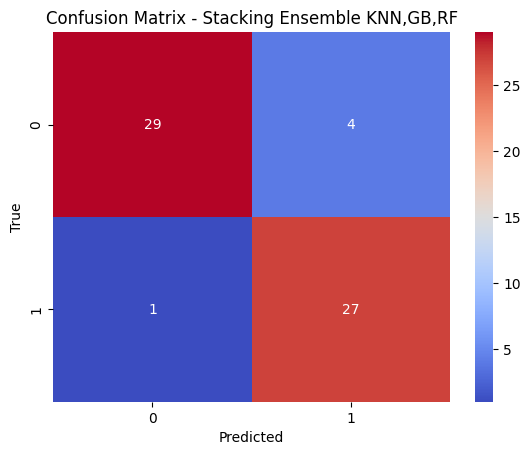

In [144]:
from sklearn.ensemble import StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Define base models
estimators = [
    ('knn', KNeighborsClassifier(n_neighbors=7, weights='distance')),
    ('gb', GradientBoostingClassifier(n_estimators=150, learning_rate=0.1)),
    ('rf', RandomForestClassifier(n_estimators=200, random_state=42))
]

# Meta model
final_estimator = LogisticRegression()

# Stacking Classifier
stack_model = StackingClassifier(
    estimators=estimators,
    final_estimator=final_estimator,
    cv=5,
    n_jobs=-1
)

# Train
stack_model.fit(X_train, y_train)

# Accuracy
print("Stacking Ensemble Accuracy:", stack_model.score(X_test, y_test))

# Predict
y_pred_stack = stack_model.predict(X_test)

# Evaluate
print("=== Stacking Ensemble Classification Report ===")
print(classification_report(y_test, y_pred_stack))

sns.heatmap(confusion_matrix(y_test, y_pred_stack), annot=True, fmt='d', cmap='coolwarm')
plt.title("Confusion Matrix - Stacking Ensemble KNN,GB,RF")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

Voting Ensemble Accuracy: 0.9344262295081968
=== Voting Ensemble Classification Report ===
              precision    recall  f1-score   support

           0       0.97      0.91      0.94        33
           1       0.90      0.96      0.93        28

    accuracy                           0.93        61
   macro avg       0.93      0.94      0.93        61
weighted avg       0.94      0.93      0.93        61



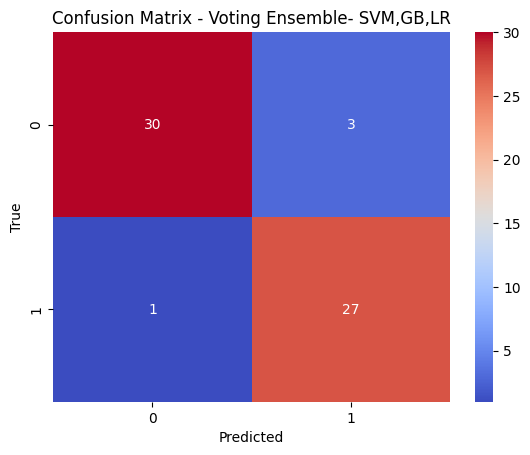

In [142]:
from sklearn.ensemble import VotingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Combine top 3 models
voting_model = VotingClassifier(
    estimators=[
        ('svm', SVC(probability=True)),
        ('gb', GradientBoostingClassifier()),
        ('lr', LogisticRegression(max_iter=1000))
    ],
    voting='soft'
)

# Train Voting Model
voting_model.fit(X_train, y_train)

# Predict for Voting Ensemble
y_pred_voting = voting_model.predict(X_test)

# Accuracy
print("Voting Ensemble Accuracy:", voting_model.score(X_test, y_test))

# Classification Report
print("=== Voting Ensemble Classification Report ===")
print(classification_report(y_test, y_pred_voting))

# Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_voting),
            annot=True, fmt='d', cmap='coolwarm')
plt.title("Confusion Matrix - Voting Ensemble- SVM,GB,LR")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

